# 02 · Preprocesamiento

En el análisis exploratorio (notebook 01) encontramos estos problemas en los datos:

1. Valores ausentes en 4 variables.
2. Valores imposibles (alcohol negativo, diastólica >= sistólica, más de 7 días de ejercicio...).
3. Variables recortadas en el percentil 99.
4. Outliers y asimetría.
5. Escalas muy distintas.
6. Clases desbalanceadas (50/30/20).
7. Incoherencias lógicas entre variables.
8. Variables categóricas y mezcla de tipos.
9. Poca correlación entre variables.

En este notebook aplicamos las técnicas de preprocesamiento para resolverlos. Las hemos programado en `src/preprocesamiento.py` para poder usarlas igual en el entrenamiento de todos los modelos. Las técnicas son:

| Técnica | Problemas que resuelve | Opciones que vamos a comparar |
|---|---|---|
| T1. Valores imposibles a NaN e imputación | 1, 2 y parte del 7 | mediana / KNN |
| T2. Escalado | 3, 4 y 5 | z-score / Yeo-Johnson |
| T3. Balanceo de clases | 6 | nada / class_weight / SMOTE-NC |
| T4. Codificación de categóricas | 8 | ordinal + one-hot |

Todo va dentro de un `Pipeline` de imbalanced-learn. Así la imputación, el escalado y SMOTE se ajustan solo con los datos de entrenamiento de cada fold y la validación y el test se quedan solo con pacientes reales, sin fuga de información.

Los problemas 7 y 9 no tienen una técnica propia: las incoherencias no se pueden corregir porque no sabemos qué variable está mal (solo anulamos las que son imposibles), y como no hay variables redundantes no hace falta quitar ninguna.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline

sys.path.append(str(Path.cwd().parent))
from src.config import (SEED, DATA_FILE, RESULTS_DIR, TARGET, CLASS_NAMES, TEST_SIZE,
                        NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES)
from src.reglas_clinicas import anular_valores_imposibles
from src.preprocesamiento import (construir_preprocesador, construir_pipeline,
                                  pesos_balanceados, todas_las_configuraciones)

np.random.seed(SEED)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
COLORES_CLASE = {0: "#4C9F70", 1: "#E0A33B", 2: "#C8553D"}

## 1. Carga y partición

Separamos train y test de forma estratificada (80/20) para que las tres clases tengan la misma proporción en los dos conjuntos. Todo el preprocesamiento se ajusta solo con train y luego se aplica a test. Usamos la misma semilla y el mismo tamaño de test que en `src/config.py`, que es la partición que se usará luego para los modelos.

In [2]:
df = pd.read_csv(DATA_FILE)
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({"train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
              "test (%)": y_test.value_counts(normalize=True).sort_index() * 100}).round(1)

Train: (1803, 27)  Test: (451, 27)


,train (%),test (%)
riesgo_cardiovascular,,
0,50.0,50.1
1,30.0,29.9
2,20.0,20.0


## 2. T1 · Valores imposibles e imputación

### 2.1 Valores imposibles a NaN

El primer paso es pasar a NaN los valores imposibles que detectamos en el EDA, usando las reglas de `src/reglas_clinicas.py`. Como las reglas son límites fijos y no se aprenden de los datos, este paso no produce fuga de información.

In [3]:
X_train_anulado = anular_valores_imposibles(X_train)
nulos = pd.DataFrame({"nulos antes": X_train[NUMERIC_FEATURES].isna().sum(),
                      "nulos después": X_train_anulado[NUMERIC_FEATURES].isna().sum()})
nulos = nulos[nulos["nulos después"] > 0].sort_values("nulos después", ascending=False)
print("Filas de train con algún nulo:", X_train.isna().any(axis=1).sum(), "->",
      X_train_anulado.isna().any(axis=1).sum())
nulos

Filas de train con algún nulo: 442 -> 633


,nulos antes,nulos después
horas_sueno_diarias,153,153
consumo_alcohol_semanal,0,146
proteina_c_reactiva,129,129
colesterol_ldl,110,111
glucosa_ayunas,92,96
presion_diastolica,0,34
presion_sistolica,0,34
frecuencia_ejercicio_semanal,0,29
colesterol_hdl,0,19
anos_fumador,0,16


### 2.2 Imputación

Después hay que rellenar los nulos. Vamos a comparar dos formas:

- **Mediana**: se sustituye cada nulo por la mediana de la variable en train. Es simple y no le afectan los outliers, pero todos los nulos de una variable reciben el mismo valor.
- **KNN** (`KNNImputer`, 5 vecinos): se buscan los 5 pacientes más parecidos según el resto de variables y se usa la media de sus valores. Aprovecha la información de las demás variables, pero es más costosa.

En el EDA vimos que los nulos no dependen de la clase, así que no añadimos una variable indicadora de "valor ausente".

En el pipeline primero escalamos y después imputamos. Si no, KNN calcularía las distancias con variables en escalas muy distintas y dominarían las que tienen números más grandes (colesterol, triglicéridos). Los dos escaladores ignoran los NaN al ajustarse, así que se puede hacer en este orden.

Comparamos cómo quedan los valores imputados del alcohol, que es la variable con más valores anulados:

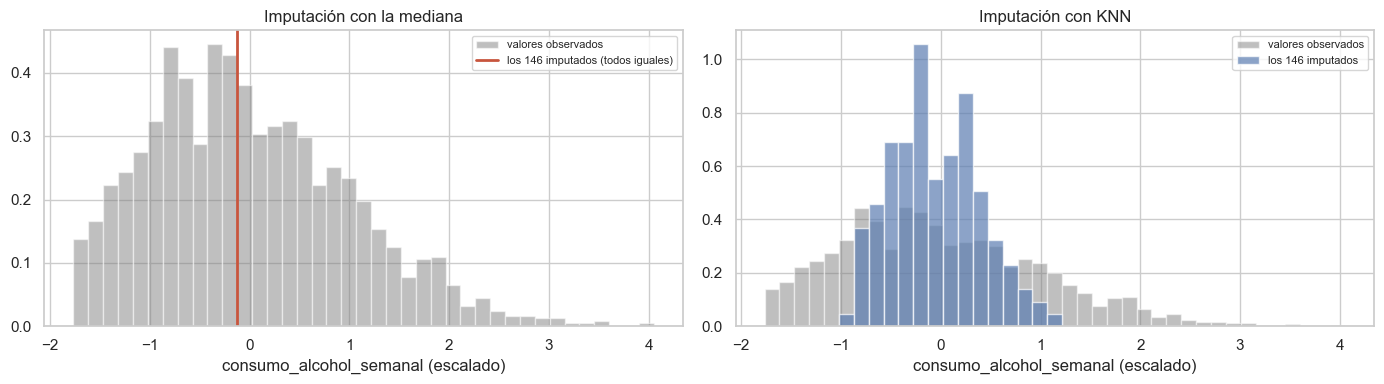

In [4]:
def preprocesar(X_fit, y_fit, X_aplicar, **config):
    # ajusta los pasos de anular e imputar con X_fit y transforma X_aplicar
    pasos = construir_preprocesador(**config)[:2]
    return Pipeline(pasos).fit(X_fit, y_fit).transform(X_aplicar)

anulados = X_train_anulado["consumo_alcohol_semanal"].isna()
con_mediana = preprocesar(X_train, y_train, X_train, imputacion="mediana")["consumo_alcohol_semanal"]
con_knn = preprocesar(X_train, y_train, X_train, imputacion="knn")["consumo_alcohol_semanal"]
bins = np.linspace(con_knn.min(), con_knn.max(), 40)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=True)
for ax, serie, titulo in [(axes[0], con_mediana, "Imputación con la mediana"),
                          (axes[1], con_knn, "Imputación con KNN")]:
    ax.hist(serie[~anulados], bins=bins, density=True, color="grey", alpha=0.5, label="valores observados")
    if titulo.endswith("mediana"):
        ax.axvline(serie[anulados].iloc[0], color="#C8553D", lw=2,
                   label=f"los {anulados.sum()} imputados (todos iguales)")
    else:
        ax.hist(serie[anulados], bins=bins, density=True, color="#5B7DB1", alpha=0.7,
                label=f"los {anulados.sum()} imputados")
    ax.set_title(titulo)
    ax.set_xlabel("consumo_alcohol_semanal (escalado)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "imputacion_mediana_vs_knn.png", dpi=150)
plt.show()

Con la mediana los 146 valores caen en el mismo punto, lo que crea un pico artificial y reduce la variabilidad. Con KNN se reparten según los pacientes parecidos, aunque quedan más concentrados en el centro que los valores reales. Cuál funciona mejor lo veremos al comparar los modelos.

## 3. T2 · Escalado

Las variables tienen escalas muy distintas y algunas son bastante asimétricas. Comparamos dos opciones:

- **Estandarización (z-score)**: resta la media y divide por la desviación típica. Todas las variables quedan con media 0 y desviación 1, pero la forma de la distribución no cambia.
- **Yeo-Johnson** (`PowerTransformer`): aplica una transformación de potencia que hace las distribuciones más simétricas y después estandariza. Además reduce el peso de los outliers. La elegimos en vez de Box-Cox porque Box-Cox no admite ceros ni negativos, y tenemos variables con ceros (años fumador, ejercicio).

Para los modelos de árboles el escalado no cambia nada, pero lo dejamos igual en todos para que la comparación sea justa.

In [5]:
asim = pd.DataFrame({
    "original": X_train_anulado[NUMERIC_FEATURES].skew(),
    "z-score": preprocesar(X_train, y_train, X_train, escalado="estandar")[NUMERIC_FEATURES].skew(),
    "Yeo-Johnson": preprocesar(X_train, y_train, X_train, escalado="yeojohnson")[NUMERIC_FEATURES].skew(),
}).round(2)
asim.sort_values("original", key=abs, ascending=False).head(8)

,original,z-score,Yeo-Johnson
proteina_c_reactiva,1.54,1.65,0.02
presion_sistolica,1.37,1.39,-0.04
trigliceridos,1.34,1.34,0.06
colesterol_total,1.32,1.32,-0.02
acido_urico,1.26,1.26,-0.02
anos_fumador,0.73,0.73,-0.16
consumo_alcohol_semanal,0.56,0.62,-0.04
glucosa_ayunas,0.19,0.19,-0.02


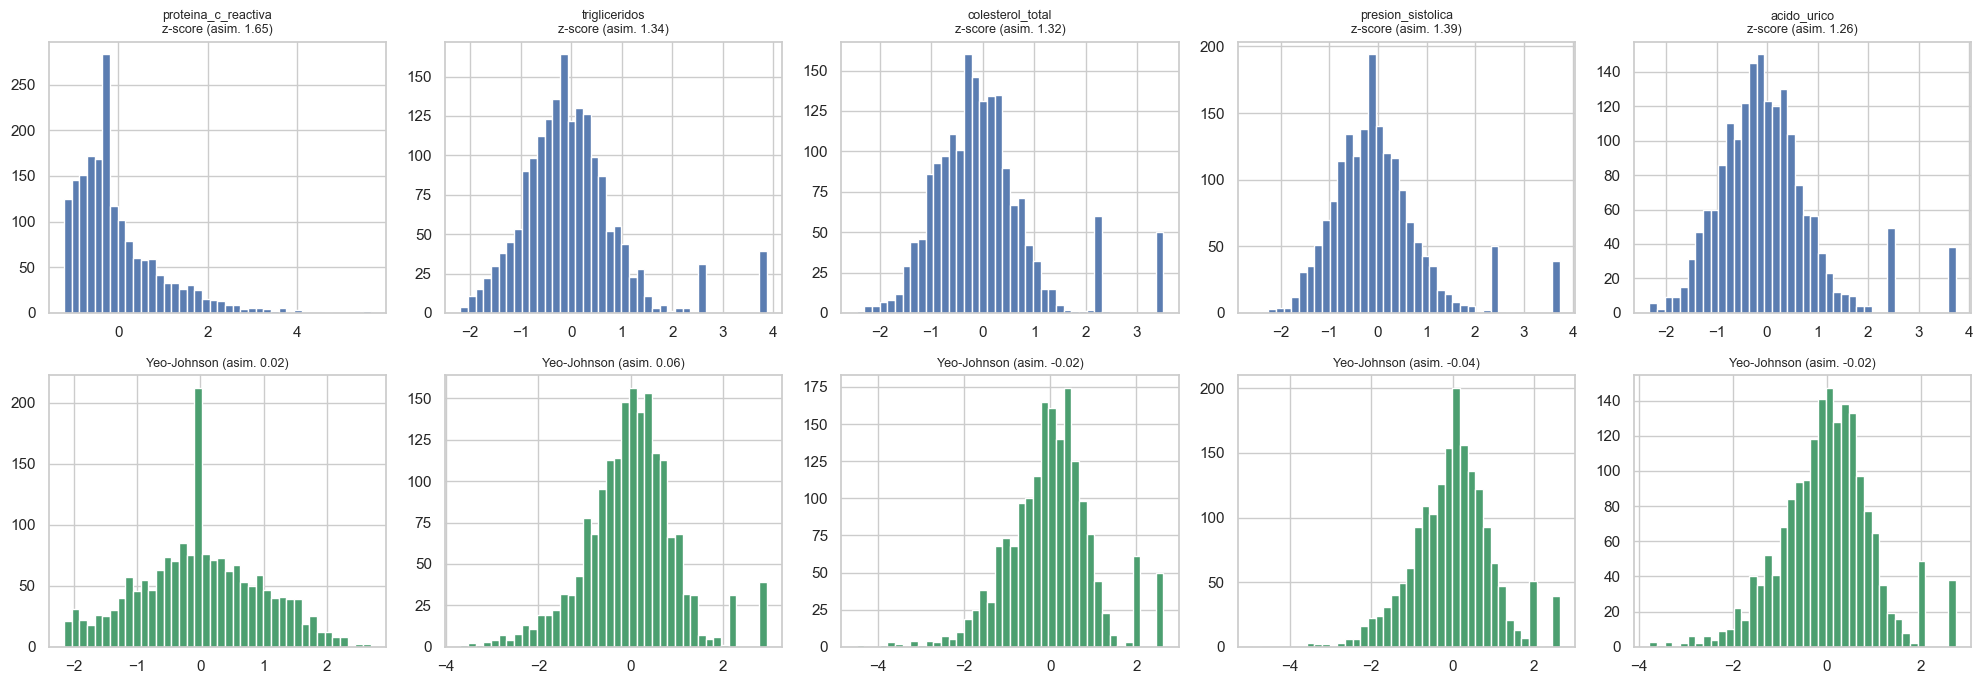

In [6]:
variables = ["proteina_c_reactiva", "trigliceridos", "colesterol_total", "presion_sistolica", "acido_urico"]
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
zs = preprocesar(X_train, y_train, X_train, escalado="estandar")
yj = preprocesar(X_train, y_train, X_train, escalado="yeojohnson")
for j, col in enumerate(variables):
    axes[0, j].hist(zs[col], bins=40, color="#5B7DB1")
    axes[0, j].set_title(f"{col}\nz-score (asim. {zs[col].skew():.2f})", fontsize=9)
    axes[1, j].hist(yj[col], bins=40, color="#4C9F70")
    axes[1, j].set_title(f"Yeo-Johnson (asim. {yj[col].skew():.2f})", fontsize=9)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "escalado_zscore_vs_yeojohnson.png", dpi=150)
plt.show()

Con Yeo-Johnson la asimetría de estas variables baja mucho, aunque el pico de los valores recortados en el máximo sigue ahí (esa información ya se perdió y no se puede recuperar).

## 4. T4 · Codificación de las categóricas

Los modelos de scikit-learn necesitan que todo sea numérico, así que codificamos las categóricas:

- `nivel_actividad` es **ordinal** (Sedentario < Ligeramente activo < Moderadamente activo < Muy activo) y en el EDA vimos que el riesgo baja según sube la actividad. La codificamos con `OrdinalEncoder` (0, 1, 2, 3) indicando el orden a mano, porque si no lo pondría por orden alfabético.
- `tipo_alimentacion` y `antecedentes_familiares_tipo` son **nominales** (no hay orden), así que usamos `OneHotEncoder`, que crea una columna 0/1 por categoría. Para los modelos lineales se puede quitar una columna de cada variable (`onehot_drop="first"`) para evitar multicolinealidad.
- Las binarias ya están en 0/1 y se dejan igual.

In [7]:
X_train_final = Pipeline(construir_preprocesador()).fit(X_train, y_train).transform(X_train)
print("Columnas antes:", X_train.shape[1], " Columnas después:", X_train_final.shape[1])
print("Valores de nivel_actividad:", sorted(X_train_final["nivel_actividad"].unique()))
X_train_final.head()

Columnas antes: 27  Columnas después: 33
Valores de nivel_actividad: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]


,nivel_actividad,tipo_alimentacion_Baja en carbohidratos,tipo_alimentacion_Mediterránea,tipo_alimentacion_Occidental,tipo_alimentacion_Vegetariana,antecedentes_familiares_tipo_Ambos,antecedentes_familiares_tipo_Materno,antecedentes_familiares_tipo_Ninguno,antecedentes_familiares_tipo_Paterno,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,horas_sueno_diarias,consumo_alcohol_semanal,anos_fumador,proteina_c_reactiva,acido_urico,clearance_creatinina,frecuencia_ejercicio_semanal,perimetro_cintura,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos
1301,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,-0.829178,0.463504,-1.538596,-0.852448,1.596091,1.838703,-0.347304,-0.184215,-0.953237,0.041553,-0.427322,-1.500184,0.507310,-0.597618,-0.584771,-1.027946,-1.013372,-0.209032,0.296185,0,1,0,0,0
1730,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.167918,2.428945,1.358062,0.011338,0.784577,-0.737215,-0.146913,1.103673,-0.343940,1.499152,1.777239,0.439177,-1.122623,-0.363241,-0.070834,-1.321369,1.362397,-0.120923,0.163832,0,0,1,0,1
1194,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,2.434046,-0.208734,1.552730,-0.091036,-1.182532,0.599551,0.113735,1.087524,0.124749,1.929264,-2.694871,-0.169250,1.360358,-0.001021,1.249864,-1.506117,1.588661,1.573481,0.897789,1,0,0,0,1
1792,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,-1.066250,0.687583,1.957639,0.060926,-1.747345,-0.479623,-1.186703,-0.026761,0.124749,0.607070,0.454502,-0.131223,2.167708,-0.416508,-1.319820,-1.000777,0.457342,0.068850,-0.606222,0,0,0,1,0
1339,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.105164,-0.398631,0.213415,0.041731,0.622274,1.852260,-0.040412,0.498083,0.468454,-0.213327,0.013590,-1.538211,-0.467603,-0.219418,-0.781979,0.238121,-0.900240,-1.666218,0.115703,0,1,0,0,0


## 5. T3 · Balanceo de clases

La clase de riesgo alto es la minoritaria y es la que más nos importa detectar. Vamos a comparar tres opciones:

- **Sin balanceo**, como referencia.
- **class_weight="balanced"**: en vez de cambiar los datos, el modelo da más peso a los errores en las clases minoritarias (aprendizaje sensible al coste). Algunos modelos como GradientBoosting o XGBoost no tienen este parámetro; en ese caso se pasan pesos por muestra al entrenar con `pesos_balanceados(y)`.
- **SMOTE-NC**: genera pacientes sintéticos de las clases minoritarias interpolando entre pacientes parecidos. Usamos la versión NC (nominal and continuous) porque tenemos variables binarias y categóricas: el SMOTE normal crearía valores como 0,4 en `diabetes_mellitus` o categorías que no existen. Por eso SMOTE va antes de codificar las categóricas.

Hay que tener en cuenta que SMOTE solo se aplica sobre el train. Al ir dentro del pipeline, en la validación cruzada se aplica solo al train de cada fold y la validación se hace siempre con pacientes reales.

In [8]:
pasos_smote = construir_preprocesador(balanceo="smotenc")
X_res, y_res = Pipeline(pasos_smote[:3]).fit_resample(X_train, y_train)

conteo = pd.DataFrame({"train original": y_train.value_counts().sort_index(),
                       "train con SMOTE-NC": pd.Series(y_res).value_counts().sort_index()})
print(conteo)
print("\nValores de las binarias tras SMOTE-NC:", {c: sorted(X_res[c].unique()) for c in BINARY_FEATURES})
print("Categorías tras SMOTE-NC:", {c: X_res[c].nunique() for c in CATEGORICAL_FEATURES})

                       train original  train con SMOTE-NC
riesgo_cardiovascular                                    
0                                 901                 901
1                                 541                 901
2                                 361                 901

Valores de las binarias tras SMOTE-NC: {'fumador_actual': [np.int64(0), np.int64(1)], 'hipertension_previa': [np.int64(0), np.int64(1)], 'diabetes_mellitus': [np.int64(0), np.int64(1)], 'tratamiento_estatinas': [np.int64(0), np.int64(1)], 'uso_antihipertensivos': [np.int64(0), np.int64(1)]}
Categorías tras SMOTE-NC: {'tipo_alimentacion': 4, 'nivel_actividad': 4, 'antecedentes_familiares_tipo': 4}


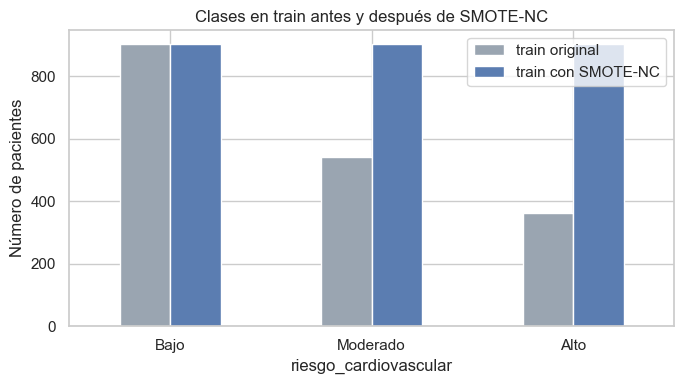

In [9]:
ax = conteo.rename(index=CLASS_NAMES).plot(kind="bar", rot=0, color=["#9AA5B1", "#5B7DB1"], figsize=(7, 4))
ax.set_ylabel("Número de pacientes")
ax.set_title("Clases en train antes y después de SMOTE-NC")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "balanceo_smotenc.png", dpi=150)
plt.show()

Las binarias siguen siendo 0/1 y las categóricas mantienen sus 4 categorías, así que SMOTE-NC no ha inventado valores que no existen.

Los pesos que se usan con `class_weight='balanced'` son inversamente proporcionales a la frecuencia de cada clase:

In [10]:
pd.Series(pesos_balanceados(y_train), index=y_train.index).groupby(y_train).first().round(3).rename("peso")

riesgo_cardiovascular
0    0.667
1    1.111
2    1.665
Name: peso, dtype: float64

## 6. Pipeline completo

Todo lo anterior se junta en `construir_pipeline(modelo, imputacion, escalado, balanceo)`, que devuelve un pipeline con estos pasos:

1. `anular`: valores imposibles a NaN.
2. `imputar`: escalado e imputación de las numéricas.
3. `smote`: solo si `balanceo="smotenc"`.
4. `codificar`: ordinal y one-hot.
5. `modelo`.

Con las opciones de cada técnica salen 12 combinaciones (2 imputaciones x 2 escalados x 3 balanceos), que se cruzarán con todos los modelos en el notebook 03.

In [11]:
configuraciones = pd.DataFrame(todas_las_configuraciones())
configuraciones.to_csv(RESULTS_DIR / "configuraciones_preprocesamiento.csv", index=False)
configuraciones

,imputacion,escalado,balanceo
0,mediana,estandar,ninguno
1,mediana,estandar,class_weight
2,mediana,estandar,smotenc
3,mediana,yeojohnson,ninguno
4,mediana,yeojohnson,class_weight
5,mediana,yeojohnson,smotenc
6,knn,estandar,ninguno
7,knn,estandar,class_weight
8,knn,estandar,smotenc
9,knn,yeojohnson,ninguno


Como comprobación, ejecutamos todas las combinaciones con una regresión logística sencilla y una validación cruzada rápida de 3 folds, solo para asegurarnos de que el pipeline funciona con todas. La comparación completa, con todos los modelos, el ajuste de hiperparámetros y las métricas, se hará en el notebook 03.

In [12]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
filas = []
for config in todas_las_configuraciones():
    pipe = construir_pipeline(LogisticRegression(max_iter=2000), **config)
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring="f1_macro")
    filas.append({**config, "f1_macro_cv": round(r["test_score"].mean(), 3)})
pd.DataFrame(filas)

,imputacion,escalado,balanceo,f1_macro_cv
0,mediana,estandar,ninguno,0.628
1,mediana,estandar,class_weight,0.631
2,mediana,estandar,smotenc,0.625
3,mediana,yeojohnson,ninguno,0.635
4,mediana,yeojohnson,class_weight,0.633
5,mediana,yeojohnson,smotenc,0.630
6,knn,estandar,ninguno,0.632
7,knn,estandar,class_weight,0.629
8,knn,estandar,smotenc,0.624
9,knn,yeojohnson,ninguno,0.634


Las 12 combinaciones funcionan sin errores. Con un modelo tan simple y sin ajustar hiperparámetros las diferencias son pequeñas, así que todavía no sacamos conclusiones sobre qué preprocesamiento es mejor.

Por último comprobamos que el pipeline ajustado con train se puede aplicar a test sin problemas (sin NaN y con las mismas columnas). Al predecir, SMOTE no se aplica: solo actúa al entrenar.

In [13]:
pipe = construir_pipeline(LogisticRegression(max_iter=2000), imputacion="knn",
                          escalado="yeojohnson", balanceo="smotenc").fit(X_train, y_train)
X_test_transformado = Pipeline(pipe.steps[:2] + pipe.steps[3:4]).transform(X_test)
print("Test transformado:", X_test_transformado.shape, "| NaN:", X_test_transformado.isna().sum().sum())
print("Predicciones en test:", len(pipe.predict(X_test)), "(mismo número de pacientes que en test)")

Test transformado: (451, 33) | NaN: 0
Predicciones en test: 451 (mismo número de pacientes que en test)


## 7. Resumen

| Problema del EDA | Técnica aplicada |
|---|---|
| Valores ausentes | Imputación con mediana o KNN |
| Valores imposibles | Pasar a NaN con reglas clínicas y después imputar |
| Valores recortados, outliers y asimetría | Yeo-Johnson (o z-score para comparar) |
| Escalas distintas | z-score o Yeo-Johnson |
| Desbalanceo | class_weight o SMOTE-NC (o nada para comparar) |
| Categóricas y tipos mixtos | Ordinal + one-hot, y SMOTE-NC en vez de SMOTE |
| Incoherencias lógicas | Solo se anulan las imposibles; el resto se deja como limitación |
| Poca correlación | No hace falta eliminar variables |

Todo está en `src/preprocesamiento.py`. Para entrenar un modelo con cualquier combinación basta con:

```python
pipe = construir_pipeline(modelo, imputacion="knn", escalado="yeojohnson", balanceo="smotenc")
```